<a href="https://colab.research.google.com/github/ShreyaBawankar77/Hack-O-Week/blob/main/Week4_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/00360/"
    "AirQualityUCI.zip"
)

import zipfile
import io
import requests

response = requests.get(url)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    df = pd.read_csv(
        z.open("AirQualityUCI.csv"),
        sep=";",
        decimal=","
    )

# Remove empty columns and rows
df = df.dropna(axis=1, how="all")
df = df.dropna(how="all")

# Clean column names
df.columns = df.columns.str.strip()

# Convert invalid sensor readings (-200) into missing values
numeric_cols = df.select_dtypes(include=np.number).columns
df[numeric_cols] = df[numeric_cols].replace(-200, np.nan)

print("Dataset shape:", df.shape)
print(df.head())
print(df.columns.tolist())

Dataset shape: (9357, 15)
         Date      Time  CO(GT)  PT08.S1(CO)  NMHC(GT)  C6H6(GT)  \
0  10/03/2004  18.00.00     2.6       1360.0     150.0      11.9   
1  10/03/2004  19.00.00     2.0       1292.0     112.0       9.4   
2  10/03/2004  20.00.00     2.2       1402.0      88.0       9.0   
3  10/03/2004  21.00.00     2.2       1376.0      80.0       9.2   
4  10/03/2004  22.00.00     1.6       1272.0      51.0       6.5   

   PT08.S2(NMHC)  NOx(GT)  PT08.S3(NOx)  NO2(GT)  PT08.S4(NO2)  PT08.S5(O3)  \
0         1046.0    166.0        1056.0    113.0        1692.0       1268.0   
1          955.0    103.0        1174.0     92.0        1559.0        972.0   
2          939.0    131.0        1140.0    114.0        1555.0       1074.0   
3          948.0    172.0        1092.0    122.0        1584.0       1203.0   
4          836.0    131.0        1205.0    116.0        1490.0       1110.0   

      T    RH      AH  
0  13.6  48.9  0.7578  
1  13.3  47.7  0.7255  
2  11.9  54.0  0.7

In [ ]:
import pickle
import joblib

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Select target and input features
target = "CO(GT)"
features = ["PT08.S1(CO)", "C6H6(GT)", "NOx(GT)", "NO2(GT)"]

data = df[features + [target]].dropna(subset=[target])

X = data[features]
y = data[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    RandomForestRegressor(n_estimators=100, random_state=42)
)

model.fit(X_train, y_train)
pred = model.predict(X_test)

print("MSE:", mean_squared_error(y_test, pred))
print("R2 score:", r2_score(y_test, pred))

# Save and load using Pickle
with open("air_quality.pkl", "wb") as f:
    pickle.dump(model, f)

with open("air_quality.pkl", "rb") as f:
    loaded_pickle = pickle.load(f)

# Save and load using Joblib
joblib.dump(model, "air_quality.joblib")
loaded_joblib = joblib.load("air_quality.joblib")

print("Pickle predictions:", loaded_pickle.predict(X_test.iloc[:5]))
print("Joblib predictions:", loaded_joblib.predict(X_test.iloc[:5]))

MSE: 0.1828965202549646
R2 score: 0.9121904543749999
Pickle predictions: [6.111 0.886 3.213 2.156 0.913]
Joblib predictions: [6.111 0.886 3.213 2.156 0.913]


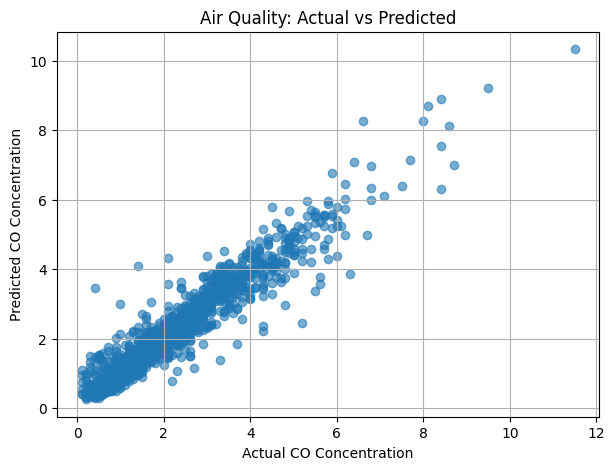

In [ ]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test, pred, alpha=0.6)
plt.xlabel("Actual CO Concentration")
plt.ylabel("Predicted CO Concentration")
plt.title("Air Quality: Actual vs Predicted")
plt.grid(True)
plt.show()

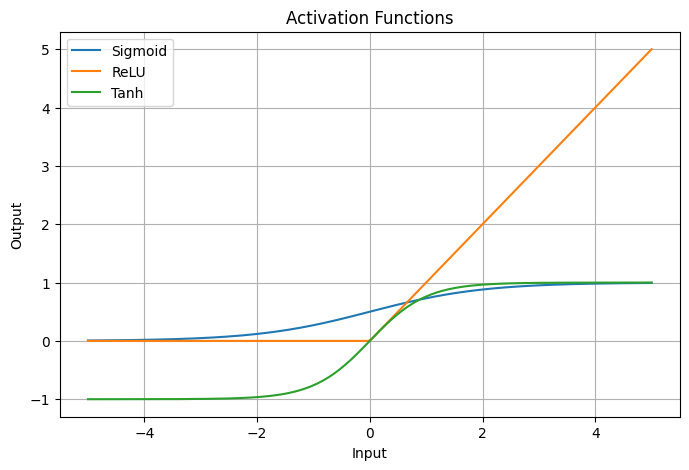

Weighted sum: 0.37000000000000005
Perceptron output: 1


In [ ]:
x = np.linspace(-5, 5, 200)

sigmoid = 1 / (1 + np.exp(-x))
relu = np.maximum(0, x)
tanh = np.tanh(x)

plt.figure(figsize=(8, 5))
plt.plot(x, sigmoid, label="Sigmoid")
plt.plot(x, relu, label="ReLU")
plt.plot(x, tanh, label="Tanh")
plt.xlabel("Input")
plt.ylabel("Output")
plt.title("Activation Functions")
plt.legend()
plt.grid(True)
plt.show()

# Basic perceptron
inputs = np.array([0.4, 0.7, 0.2])
weights = np.array([0.5, 0.3, 0.8])
bias = -0.2

z = np.dot(inputs, weights) + bias
output = 1 if z >= 0 else 0

print("Weighted sum:", z)
print("Perceptron output:", output)